In [ ]:
# Possible prerequisites:
# ========================
# !pip install causal-conv1d
# BRANCH = "r2.4.0"
# !pip install torch==2.4.0
# !pip install causal-conv1d>=1.4.0
# !pip install torch
# !pip install "nemo_toolkit[all] @ git+https://github.com/NVIDIA/NeMo.git@$BRANCH"


### Prepare pretrained NeMo VAD model

In [ ]:
import torch
import nemo.collections.asr as nemo_asr
vad_model = nemo_asr.models.EncDecFrameClassificationModel.from_pretrained(model_name="nvidia/frame_vad_multilingual_marblenet_v2.0", strict=False)
device = "cpu"
vad_model = vad_model.to(device)
vad_model.eval()

In [ ]:
# Export to onnx
vad_model.export("marblenet2.onnx")

### Feature computation code (uses filterbank with n_mels=80)

In [ ]:
# based on https://github.com/istupakov/onnx-asr/blob/main/preprocessors/nemo.py
import torchaudio
from onnxscript import opset17 as op
from onnx import TensorProto
import librosa
import numpy as np

def normalize(x, lens):
    lens_3d = op.Unsqueeze(lens, [1, 2])
    mask = op.Range(0, op.Shape(x, start=2, end=3), 1) < lens_3d
    lens_3d = op.CastLike(lens_3d, x)
    mean = op.ReduceSum(op.Where(mask, x, 0), axes=[-1], keepdims=1) / lens_3d
    var = op.ReduceSumSquare(op.Where(mask, x - mean, 0), axes=(-1,), keepdims=1) / (lens_3d - 1)
    return op.Where(mask, (x - mean) / (op.Sqrt(var) + 1e-5), 0)

def compute_mel2(path):
    sample_rate = 16_000
    n_fft = 512
    win_length = 400
    hop_length = 160
    preemph = 0.97
    log_zero_guard_value = float(2**-24)

    melscale_fbanks = torchaudio.functional.melscale_fbanks(
        n_fft // 2 + 1, 0, sample_rate // 2, 80, sample_rate, "slaney", "slaney"
    ).numpy()
    #print(melscale_fbanks.shape)

    waveforms, _ = librosa.load(path, sr=sample_rate)
    waveforms = librosa.util.normalize(waveforms, norm=np.inf)  # <<-- crucial
    waveforms_lens = np.expand_dims(waveforms.shape[0], axis=0)
    waveforms = np.expand_dims(waveforms, axis=0)

    waveforms = op.Pad(
        waveforms,
        pads=op.Constant(value=[0, n_fft // 2, 0, n_fft // 2]),
        mode="reflect",
    )
    hann_window = op.Pad(
        op.HannWindow(win_length, periodic=0, output_datatype=TensorProto.DOUBLE),
        pads=op.Constant(value=[n_fft // 2 - win_length // 2, n_fft // 2 - win_length // 2]),
    )
    image = op.STFT(op.CastLike(waveforms, hann_window), hop_length, hann_window)
    spectrogram = op.ReduceSumSquare(image, axes=(-1,), keepdims=0)

    mel_spectrogram = op.MatMul(op.CastLike(spectrogram, melscale_fbanks), melscale_fbanks)
    log_mel_spectrogram = op.Log(mel_spectrogram + log_zero_guard_value)

    features_lens = np.int64(waveforms_lens / hop_length + 1)
    return op.Transpose(log_mel_spectrogram, perm=(0, 2, 1)), features_lens
    #return normalize(op.Transpose(log_mel_spectrogram, perm=(0, 2, 1)), features_lens), features_lens

### NeMo VAD onnx inference

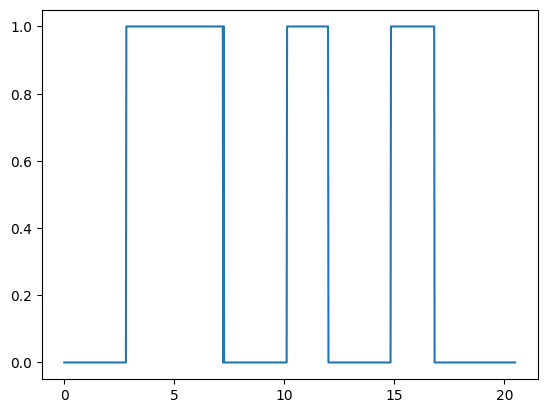

In [ ]:
import torch
audio_path = "vad_test.wav"

# Important: do not normalize log mel spectrogram, only audio!
processed_signal, length = compute_mel2(audio_path)
processed_signal = processed_signal.value
input_signal_length = length[0] * 0.010 * 16000

import onnxruntime as ort
session = ort.InferenceSession("marblenet2.onnx")
out = session.run(output_names=["outputs"], input_feed={ "audio_signal": processed_signal })
out = out[0][0]
out = np.argmax(out, axis=1) > 0.5
import matplotlib.pyplot as plt
plt.figure()
x = np.linspace(0, input_signal_length/16000, out.shape[0])
#plt.locator_params(axis='x', nbins=40)
plt.plot(x, out)

### For comparison, direct inference using pretrained .nemo model

torch.Size([1025, 2])


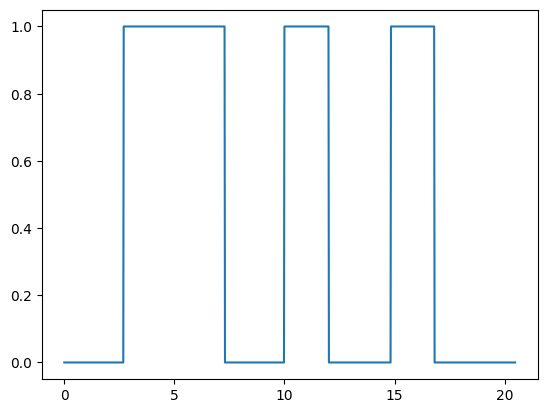

In [ ]:
import librosa
import torch
import numpy as np

# Load the audio
audio_path = "vad_test.wav"
input_signal = librosa.load(audio_path, sr=16000, mono=True)[0]
input_signal = torch.tensor(input_signal).unsqueeze(0).float()
input_signal_length = torch.tensor([input_signal.shape[1]]).long()

# Perform inference
with torch.no_grad():
   torch_outputs = vad_model(
        input_signal=input_signal.to(device),
        input_signal_length=input_signal_length.to(device)
    ).cpu()

out = torch_outputs[0]
print(out.shape)
out = np.argmax(out, axis=1) > 0.5

import matplotlib.pyplot as plt
plt.figure()
x = np.linspace(0, input_signal_length/16000, out.shape[0])
plt.plot(x, out)

### Test inference using Silero VAD

In [ ]:
import silero_vad
from silero_vad import load_silero_vad, read_audio, get_speech_timestamps
print(silero_vad.__file__)
model = load_silero_vad(onnx=True, opset_version=15)
wav = read_audio(audio_path)
speech_timestamps = get_speech_timestamps(
  wav,
  model,
  return_seconds=True,  # Return speech timestamps in seconds (default is samples)
)
print(speech_timestamps)